In [ ]:
%matplotlib inline

# Solution 4 (optional) — Desqueeze the interaction points

Increase both IP beta functions by a factor of ten, from 0.09 m / 0.0008 m to 0.9 m / 0.008 m. Keep a waist at the IP: $\alpha_x=\alpha_y=0$.

Match the two halves of the straight around `ipd`, keeping the nominal optics at the outer boundaries. The quadrupole circuits are shared by the four experimental insertions, so all four IPs change together. Complete the missing code. Restore the nominal tunes and chromaticities with the arc circuits.

### Load the nominal lattice

In [1]:
import xtrack as xt

env = xt.load('fccee_z.json')
env.vars.load('optics_nominal.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)
tw0 = line.twiss4d(delta_chrom=1e-6)

### Inspect the experimental straight

In [2]:
ip = 'ipd'
start = 'end_ds_start_straight_ipd'
end = 'end_straight_start_ds_ipd'

tw0.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02472
ipd                             22665.1          0.09        0.0008  -5.88247e-09  -2.53742e-08
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02473

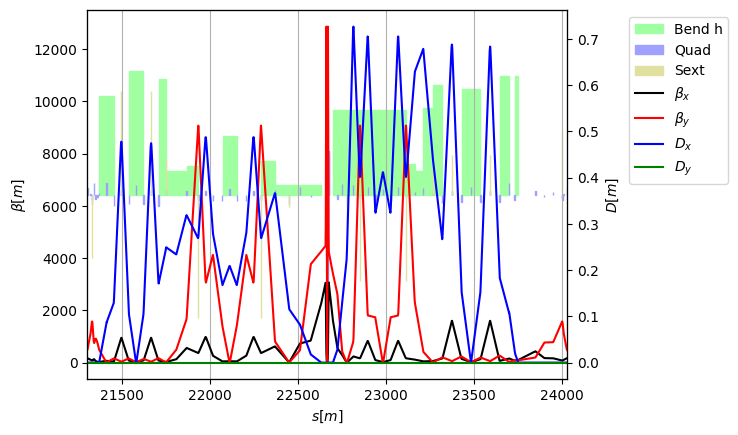

In [3]:
tw0.rows[start:end].plot()

### Quadrupoles for matching

Use the quadrupoles in the nominally dispersion-free matching sections. The supplied lattice already has independent knobs for the left and right sides. Keep the final-focus and dispersion-suppressor magnets fixed.

In [4]:
knobs_left = ['kqd16l', 'kqf17l', 'kqd18l', 'kqf19l', 'kqd20l',
              'kqd8m', 'kqf9m', 'kqd10m']
knobs_right = ['kqf17r', 'kqd18r', 'kqf19r', 'kqd20r',
               'kqd8mr', 'kqf9mr', 'kqd10mr']

### Fix the boundary optics

Use the nominal Twiss parameters at the two outer boundaries as initial conditions for open matching.

In [5]:
init_left = tw0.get_twiss_init(start)
init_right = tw0.get_twiss_init(end)

### Set the IP targets

Target ten times the nominal beta functions and zero alpha in both planes. The supplied weights account for the different horizontal and vertical beta scales.

In [6]:
beta_factor = 10

targets_ip = [
    xt.Target('betx', at=ip, value=beta_factor * tw0['betx', ip], tol=1e-8, weight=10),
    xt.Target('bety', at=ip, value=beta_factor * tw0['bety', ip], tol=1e-10, weight=1000),
    xt.TargetSet(alfx=0, alfy=0, at=ip, tol=1e-7),
]

### Match the left half

Propagate from `start` to `ip` using `init_left` and vary `knobs_left`. `line.match` solves the matching problem directly.

In [7]:
opt_left = line.match(
    method='4d',
    start=start, end=ip, init=init_left,
    vary=xt.VaryList(knobs_left, step=1e-8),
    targets=targets_ip,
    n_steps_max=80,
)

                                             
Optimize - start penalty: 10.84                         

Optimize - end penalty:  5.55777e-10                            


In [8]:
opt_left.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx    True   2.28824e-11           0.9           0.9 ('betx', 'ipd'), val=0.9, tol=1e-08, wei ...
1  ON    ipd_bety    True  -2.88174e-13         0.008         0.008 ('bety', 'ipd'), val=0.008, tol=1e-10, w ...
2  ON    ipd_alfx    True   4.15834e-11   4.15834e-11             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   2.37908e-12   2.37908e-12             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


### Match the right half

Use the range from `ip` to `end`, with `init_right` specified at `end`. Set `init_at=end` to propagate backwards from the downstream boundary.

In [9]:
opt_right = line.match(
    method='4d',
    start=ip, end=end, init=init_right, init_at=end,
    vary=xt.VaryList(knobs_right, step=1e-8),
    targets=targets_ip,
    n_steps_max=80,
)

                                             
Optimize - start penalty: 10.84                         

Optimize - end penalty:  1.51186e-07                            


In [10]:
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx    True    1.4371e-09           0.9           0.9 ('betx', 'ipd'), val=0.9, tol=1e-08, wei ...
1  ON    ipd_bety    True   2.43619e-11         0.008         0.008 ('bety', 'ipd'), val=0.008, tol=1e-10, w ...
2  ON    ipd_alfx    True  -1.48182e-08  -1.48182e-08             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   9.96264e-10   9.96264e-10             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


### Inspect the matched straight

Propagate through the entire straight from the fixed left boundary. Compare the IP beta functions and the recovered right-boundary optics with the nominal table above.

In [11]:
tw_local = line.twiss4d(start=start, end=end, init=init_left)
tw_local.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02472
ipd                             22665.1           0.9         0.008   4.15834e-11   2.37908e-12
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02473

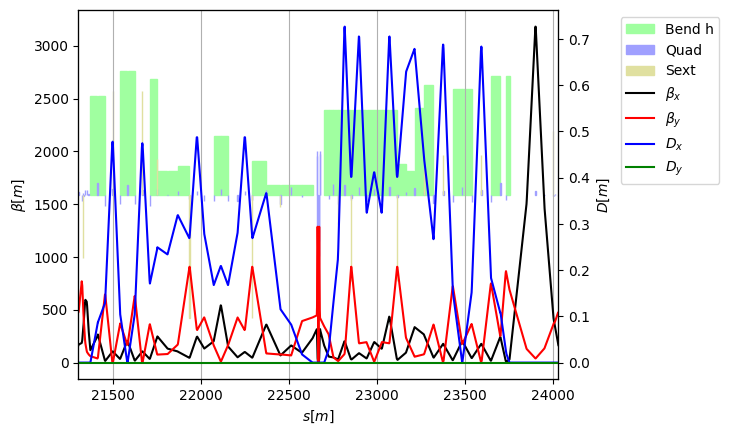

In [12]:
tw_local.plot()

### Restore the tunes

Use the arc quadrupole circuits `kqf2` and `kqd1` to recover the nominal tunes from `tw0`.

In [13]:
opt_tunes = line.match(
    method='4d',
    vary=xt.VaryList(['kqf2', 'kqd1'], step=1e-8),
    targets=xt.TargetSet(qx=tw0.qx, qy=tw0.qy, tol=1e-8),
)

                                             
Optimize - start penalty: 3.713                         

Optimize - end penalty:  8.18016e-09                            


### Restore the chromaticities

Use the arc sextupole families `ksf1` and `ksd1` to recover the nominal chromaticities. Keep `delta_chrom=1e-6`, as in the nominal calculation.

In [14]:
opt_chroma = line.match(
    method='4d', delta_chrom=1e-6,
    vary=xt.VaryList(['ksf1', 'ksd1'], step=1e-5),
    targets=xt.TargetSet(dqx=tw0.dqx, dqy=tw0.dqy, tol=1e-3),
)

                                             
Optimize - start penalty: 51.37                         

Optimize - end penalty:  5.20242e-06                            


### Check the periodic ring

Recalculate the periodic optics and check all four IPs, tunes, and chromaticities. The arc quadrupole adjustment can slightly change the IP beta functions.

In [15]:
tw = line.twiss4d(delta_chrom=1e-6)
tw.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['betx bety alfx alfy']

TwissTable: 4 rows, 5 cols
name          betx          bety          alfx          alfy
ipa        0.89789    0.00799084  -0.000199031   0.000961198
ipd        0.89789    0.00799084   -0.00019903   0.000961261
ipg        0.89789    0.00799084  -0.000199023   0.000961268
ipj        0.89789    0.00799084  -0.000199038   0.000961114

In [16]:
print('Nominal tunes:', tw0.qx, tw0.qy)
print('Desqueezed tunes:', tw.qx, tw.qy)

Nominal tunes: 166.1600000002857 162.20000000205482
Desqueezed tunes: 166.16000000088516 162.2000000014979


In [17]:
print('Nominal chromaticities:', tw0.dqx, tw0.dqy)
print('Desqueezed chromaticities:', tw.dqx, tw.dqy)

Nominal chromaticities: 6.477731091614197 7.81195859709134
Desqueezed chromaticities: 6.477725890441371 7.811958483404502
